# Phase 3 — Preprocessing: FD004
**Notebook:** `12_Preprocessing_FD004.ipynb` · **Project:** Intelligent Predictive Maintenance — RUL Estimation

Turns the `11_EDA_FD004` findings into a frozen, leakage-safe pipeline. It follows the same steps as FD001/FD002 and reuses the same `src/` code, with no new files.

| Step | What | Decided by |
|---|---|---|
| 1 | Split by **engine**, 80/20, seed 42 | Same rule as every dataset |
| 2 | Test-like validation points, minimum history = shortest test engine | Same rule as FD002 |
| 3 | **Experiment A:** global vs per-regime scaling | Validation |
| 4 | **Experiment B:** core 14 sensors vs the rule-based sensor set | Validation |
| 5 | **Experiment C:** RUL cap (none / 100 / 125 / 150) | Validation |
| 6 | Freeze, save and reload-check | — |

**Decision rules are fixed in advance and applied by the code** (you can override them in Cell 9):
- **Sensors:** use the core 14 unless the rule-based set is better by **more than 0.5** RF RMSE. Simpler wins ties.
- **Cap:** keep **125** (a consistent meaning, "≥ 125 = healthy", across datasets) unless another cap beats it by **more than 2.0** RF RMSE on true RUL ≤ 125. This is the same judgement used for FD001 and FD002, now written as an explicit number.

🔒 Official test **labels** are not used. Only test **lengths** (and, for regimes, test settings) are checked.
⚙️ CPU is fine, about 3–6 minutes.

## Cell 1 — Setup

In [1]:
# Cell 1 — Setup
import os, sys, json, time, importlib
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

try:
    from google.colab import drive
    drive.mount('/content/drive')
    RAW_DIR     = Path("/content/drive/MyDrive/CMAPSSData")
    PROJECT_DIR = Path("/content/drive/MyDrive/Predictive_Maintenance_RUL")
except ImportError:
    RAW_DIR     = Path(os.environ["CMAPSS_RAW_DIR"])
    PROJECT_DIR = Path(os.environ["PROJECT_DIR"])

FD, SEED = "FD004", 42
PROC_DIR    = PROJECT_DIR / "data" / "processed" / FD
PREP_REPORT = PROJECT_DIR / "reports" / "preprocessing" / FD
FIG_DIR     = PROJECT_DIR / "reports" / "figures" / FD
ART_DIR     = PROJECT_DIR / "models" / FD / "preprocessing"
for p in (PROC_DIR, PREP_REPORT, FIG_DIR):
    p.mkdir(parents=True, exist_ok=True)
sys.path.insert(0, str(PROJECT_DIR))
pd.set_option("display.max_columns", None); pd.set_option("display.width", 200)

import src.data_loader as dl, src.preprocessing as pp, src.evaluation as ev
import src.feature_engineering as fe, src.regime_preprocessing as rp
for m in (dl, pp, ev, fe, rp):
    importlib.reload(m)
print("Ready")

Ready


## Cell 2 — Load and split by engine

In [2]:
# Cell 2 — Split (engine-wise) and save
d = dl.load_dataset(FD, RAW_DIR)
train_ids, val_ids = pp.split_engines(d["train"], val_fraction=0.2, seed=SEED)
assert not set(train_ids) & set(val_ids)
full = pp.add_train_rul(d["train"])
tr = full[full.engine_id.isin(train_ids)].reset_index(drop=True)
va = full[full.engine_id.isin(val_ids)].reset_index(drop=True)
(PROC_DIR / "split.json").write_text(json.dumps({"dataset": FD, "seed": SEED, "val_fraction": 0.2,
                                                 "train_engine_ids": train_ids, "val_engine_ids": val_ids}))
print(f"train engines {len(train_ids)} ({len(tr)} rows) | validation engines {len(val_ids)} ({len(va)} rows)")

train engines 199 (49147 rows) | validation engines 50 (12102 rows)


## Cell 3 — Test-like validation points
10 random stop points per validation engine, scored against the **true, uncapped** RUL. The minimum history is the shortest test engine (only its length is used).

In [3]:
# Cell 3 — Validation cut points
MIN_HISTORY = int(d["test"].groupby("engine_id").cycle.max().min())
cuts = pp.make_eval_cut_points(va, n_cuts=10, min_history=MIN_HISTORY, seed=SEED)
cuts.to_csv(PROC_DIR / "val_cut_points.csv", index=False)
bands = pd.cut(cuts.true_rul, [-1, 50, 125, 10000], labels=["0-50", "51-125", ">125"])
print(f"Shortest test history: {MIN_HISTORY} → {len(cuts)} points from {cuts.engine_id.nunique()} engines")
print("points per band:", bands.value_counts().sort_index().to_dict())

Shortest test history: 19 → 500 points from 50 engines
points per band: {'0-50': 127, '51-125': 192, '>125': 181}


## Cell 4 — Learn the operating regimes (training engines only) and check every row is covered

In [4]:
# Cell 4 — Regimes
probe_prep = rp.RegimePreprocessor().fit(tr)      # default rule: drop sensors with < 3 values in every regime
c = probe_prep.regime_centers.copy()
c["train_rows"] = probe_prep.assign_regime(tr).value_counts().sort_index()
c["val_rows"]   = probe_prep.assign_regime(va).value_counts().sort_index()
c["test_rows"]  = probe_prep.assign_regime(d["test"]).value_counts().sort_index()      # settings only
display(c.round(3))
RULE_SET = probe_prep.feature_cols
print("Rule-based sensor set:", RULE_SET)

,op_setting_1,op_setting_2,op_setting_3,train_rows,val_rows,test_rows
regime,,,,,,
1,0.002,0.000,100.0,7409,1829,6054
2,10.003,0.251,100.0,7408,1816,6185
3,20.003,0.701,100.0,7312,1779,6254
4,25.003,0.621,60.0,7346,1793,6107
5,35.003,0.841,100.0,7323,1839,6232
6,42.003,0.840,100.0,12349,3046,10382


Rule-based sensor set: ['sensor_2', 'sensor_3', 'sensor_4', 'sensor_6', 'sensor_7', 'sensor_8', 'sensor_9', 'sensor_10', 'sensor_11', 'sensor_12', 'sensor_13', 'sensor_14', 'sensor_15', 'sensor_17', 'sensor_20', 'sensor_21']


---
## Probe models (same as FD002)
Linear Regression and a small Random Forest (60 trees), using the **rolling-30 features** the real models use, scored on the validation points. Main metric: **RMSE where true RUL ≤ 125**.

In [5]:
# Cell 5 — Probe function
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
y = cuts.true_rul.values
LE, MID = y <= 125, (y > 50) & (y <= 125)
CORE_14 = [f"sensor_{i}" for i in (2, 3, 4, 7, 8, 9, 11, 12, 13, 14, 15, 17, 20, 21)]

def make_prep(kind, cols):
    return (rp.RegimePreprocessor(feature_cols=cols) if kind == "regime"
            else pp.CMAPSSPreprocessor(scaler="standard", feature_cols=cols)).fit(tr)

def probe(preprocessor, base_cols, cap, label):
    data = preprocessor.transform(pp.add_train_rul(d["train"], cap=cap))
    feats, names = fe.build_tabular(data, base_cols, 30, include_cycle=True)
    a = feats[feats.engine_id.isin(train_ids)]
    X = fe.rows_at(feats[feats.engine_id.isin(val_ids)], cuts)[names]
    rows = []
    for name, model in {"LR": LinearRegression(),
                        "RF": RandomForestRegressor(n_estimators=60, min_samples_leaf=5, max_features=0.33,
                                                    max_samples=0.5, n_jobs=-1, random_state=SEED)}.items():
        t0 = time.time(); model.fit(a[names], a["RUL"]); pred = np.clip(model.predict(X), 0, None)
        rows.append({"variant": label, "probe": name, "cap": "none" if cap is None else cap, "n_features": len(names),
                     "RMSE_le125": ev.rmse(y[LE], pred[LE]), "NASA_per_point_le125": ev.nasa_score(y[LE], pred[LE]) / LE.sum(),
                     "bias_51_125": float(np.mean(pred[MID] - y[MID])), "RMSE_gt125": ev.rmse(y[~LE], pred[~LE]),
                     "RMSE_all": ev.rmse(y, pred), "fit_seconds": round(time.time() - t0, 1)})
    print(f"{label:28s} cap={rows[0]['cap']}: LR {rows[0]['RMSE_le125']:.2f} | RF {rows[1]['RMSE_le125']:.2f}")
    return rows
rf_of = lambda df, **kw: df[(df.probe == "RF") & np.logical_and.reduce([df[k] == v for k, v in kw.items()])].RMSE_le125.iloc[0]

## Experiment A — Global vs per-regime scaling
Repeats FD002's key experiment. The global pipeline keeps the settings as inputs, so a model could learn the regime offsets itself.

In [6]:
# Cell 6 — Experiment A
glob = pp.CMAPSSPreprocessor(scaler="standard").fit(tr)
rows = probe(glob, glob.feature_cols, 125, "global (+settings)") + probe(make_prep("regime", CORE_14), CORE_14, 125, "per-regime, core 14")
expA = pd.DataFrame(rows); expA.to_csv(PREP_REPORT / "experiment_A_normalisation.csv", index=False)
display(expA.round(2))
KIND = "regime" if rf_of(expA, variant="per-regime, core 14") <= rf_of(expA, variant="global (+settings)") else "global"
print("→ scaling:", KIND)

global (+settings)           cap=125: LR 25.24 | RF 23.21


per-regime, core 14          cap=125: LR 24.34 | RF 18.15


,variant,probe,cap,n_features,RMSE_le125,NASA_per_point_le125,bias_51_125,RMSE_gt125,RMSE_all,fit_seconds
0,global (+settings),LR,125,85,25.24,23.12,8.90,94.51,60.33,0.1
1,global (+settings),RF,125,85,23.21,18.74,8.92,96.56,60.98,5.0
2,"per-regime, core 14",LR,125,57,24.34,20.61,9.03,94.52,60.10,0.1
3,"per-regime, core 14",RF,125,57,18.15,8.92,9.93,94.67,58.78,3.6


→ scaling: regime


## Experiment B — Core 14 sensors vs the rule-based set
The rule-based set also keeps the extra sensors with ≥ 3 distinct values (for example `sensor_6`, `sensor_10`). Are they worth it?

In [7]:
# Cell 7 — Experiment B
SETS = {"core 14": CORE_14, f"rule-based ({len(RULE_SET)})": RULE_SET}
rows = []
for label, cols in SETS.items():
    rows += probe(make_prep("regime" if KIND == "regime" else "global", cols), cols, 125, label)
expB = pd.DataFrame(rows); expB.to_csv(PREP_REPORT / "experiment_B_feature_set.csv", index=False)
display(expB.round(2))
gain = rf_of(expB, variant="core 14") - rf_of(expB, variant=f"rule-based ({len(RULE_SET)})")
FEATURES = RULE_SET if gain > 0.5 else CORE_14
print(f"RF gain from the extra sensors: {gain:+.2f} → using {'rule-based set' if FEATURES is RULE_SET else 'core 14'} ({len(FEATURES)} sensors)")

core 14                      cap=125: LR 24.34 | RF 18.15


rule-based (16)              cap=125: LR 24.26 | RF 18.36


,variant,probe,cap,n_features,RMSE_le125,NASA_per_point_le125,bias_51_125,RMSE_gt125,RMSE_all,fit_seconds
0,core 14,LR,125,57,24.34,20.61,9.03,94.52,60.10,0.1
1,core 14,RF,125,57,18.15,8.92,9.93,94.67,58.78,3.4
2,rule-based (16),LR,125,65,24.26,20.51,9.39,95.39,60.57,0.1
3,rule-based (16),RF,125,65,18.36,9.56,9.98,94.49,58.71,4.2


RF gain from the extra sensors: -0.21 → using core 14 (14 sensors)


## Experiment C — RUL cap
Same candidates as FD001/FD002. The code applies the rule from the top of the notebook.

chosen features              cap=none: LR 52.76 | RF 36.78


chosen features              cap=100: LR 20.46 | RF 15.39


chosen features              cap=125: LR 24.34 | RF 18.15


chosen features              cap=150: LR 30.66 | RF 23.57


,probe,cap,n_features,RMSE_le125,NASA_per_point_le125,bias_51_125,RMSE_gt125,RMSE_all,fit_seconds
0,LR,none,57,52.76,9252.09,47.42,56.62,54.19,0.1
1,RF,none,57,36.78,6848.36,30.14,56.73,45.03,3.4
2,LR,100,57,20.46,7.97,-4.65,111.41,69.00,0.1
3,RF,100,57,15.39,3.97,-0.82,112.14,68.58,3.9
4,LR,125,57,24.34,20.61,9.03,94.52,60.10,0.1
5,RF,125,57,18.15,8.92,9.93,94.67,58.78,3.6
6,LR,150,57,30.66,67.78,19.99,81.26,54.68,0.1
7,RF,150,57,23.57,30.03,18.16,80.81,52.14,3.6


Best RF cap: 100 (15.39); cap 125: 18.15 → chosen cap 100


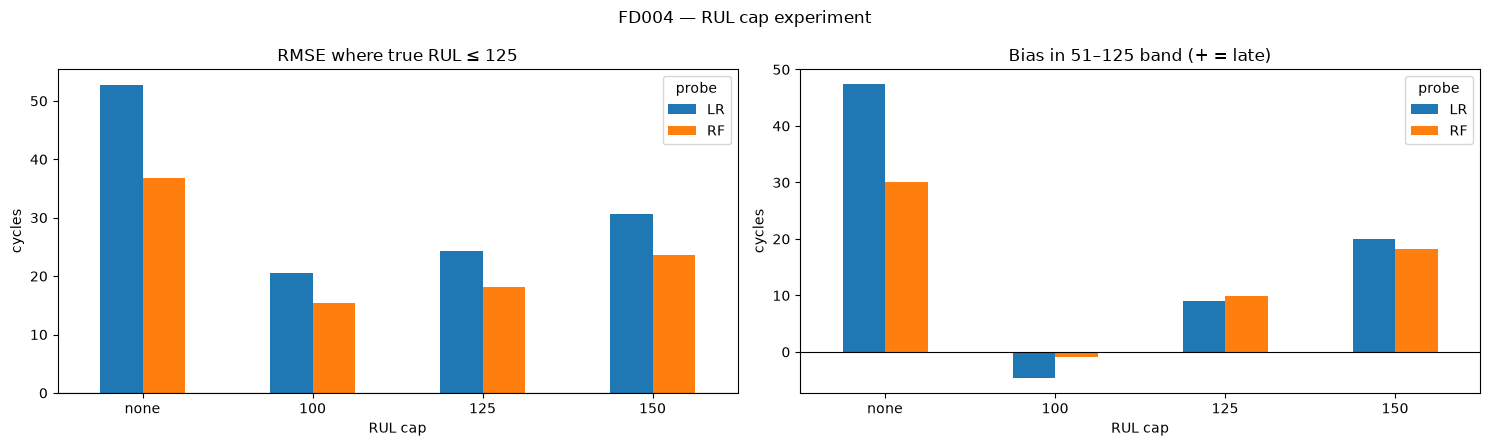

In [8]:
# Cell 8 — Experiment C
final_kind = "regime" if KIND == "regime" else "global"
prep_c = make_prep(final_kind, FEATURES)
rows = []
for cap in [None, 100, 125, 150]:
    rows += probe(prep_c, FEATURES, cap, "chosen features")
expC = pd.DataFrame(rows); expC.to_csv(PREP_REPORT / "rul_cap_experiment.csv", index=False)
display(expC.drop(columns="variant").round(2))
rf_c = expC[expC.probe == "RF"].set_index("cap")
best_cap = rf_c.RMSE_le125.idxmin()
CAP = 125 if rf_c.loc[125, "RMSE_le125"] <= rf_c.RMSE_le125.min() + 2.0 else best_cap
print(f"Best RF cap: {best_cap} ({rf_c.RMSE_le125.min():.2f}); cap 125: {rf_c.loc[125, 'RMSE_le125']:.2f} → chosen cap {CAP}")

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
for ax, metric, title in [(axes[0], "RMSE_le125", "RMSE where true RUL ≤ 125"), (axes[1], "bias_51_125", "Bias in 51–125 band (+ = late)")]:
    expC.pivot(index="cap", columns="probe", values=metric).loc[["none", 100, 125, 150]].plot.bar(ax=ax, rot=0)
    ax.axhline(0, color="black", lw=0.8); ax.set(title=title, xlabel="RUL cap", ylabel="cycles")
fig.suptitle(f"{FD} — RUL cap experiment"); fig.tight_layout()
fig.savefig(FIG_DIR / "10_rul_cap_experiment.png", dpi=150, bbox_inches="tight"); plt.show()

**How to read it:** as in FD001/FD002, no cap usually gives large **late** errors at RUL ≤ 125. Lower caps are more accurate near failure but say nothing beyond the cap. The printed line shows which rule applied.

## Cell 9 — Freeze, save and reload-check

In [9]:
# Cell 9 — Freeze the pipeline
# (Override here if you disagree with a rule-based choice, e.g. CAP = 100 or FEATURES = CORE_14)
final_prep = make_prep(final_kind, FEATURES)
final_prep.save(ART_DIR)
candidates = [c for c in dl.FEATURE_CANDIDATES if c not in FEATURES]
dropped = {**{c: "operational setting (" + ("used only to identify the operating regime" if final_kind == "regime"
                                            else "single operating condition -> noise") + ")"
              for c in dl.SETTING_COLS},
           **{c: getattr(final_prep, "dropped_features", {}).get(c) or "not selected (constant, or Experiment B)"
              for c in candidates if c.startswith("sensor_")}}
metadata = {
    "dataset": FD, "kind": final_kind,
    "scaler": "standard, fitted separately per operating regime" if final_kind == "regime" else "standard",
    "feature_cols": FEATURES, "dropped_features": dropped, "rul_cap": int(CAP),
    "rul_cap_meaning": f"predictions near {CAP} mean 'RUL >= {CAP} cycles (healthy)'",
    "prediction_postprocessing": "clip predictions to >= 0",
    "min_history": MIN_HISTORY, "max_lstm_seq_len": MIN_HISTORY,
    "split_file": f"data/processed/{FD}/split.json", "val_cut_points_file": f"data/processed/{FD}/val_cut_points.csv",
    "fit_on": f"{len(train_ids)} training engines (seed {SEED})",
    "metric_sign_convention": "d = predicted - true; d > 0 is late (dangerous)",
}
(ART_DIR / "pipeline_metadata.json").write_text(json.dumps(metadata, indent=2))
reloaded = rp.load_preprocessor(ART_DIR)
for name, df_ in [("train", tr), ("validation", va), ("test", d["test"])]:
    assert np.allclose(final_prep.transform(df_)[FEATURES].values, reloaded.transform(df_)[FEATURES].values), name
print(f"✅ {FD} pipeline saved + reload verified → {type(reloaded).__name__}, {len(FEATURES)} sensors, cap {CAP}, "
      f"min history {MIN_HISTORY}")
print(sorted(p.name for p in ART_DIR.iterdir()))
(PREP_REPORT / "preprocessing_log.json").write_text(json.dumps({
    "scaling": final_kind, "features": FEATURES, "chosen_cap": int(CAP), "min_history": MIN_HISTORY,
    "rules": {"features": "core 14 unless rule-based set better by > 0.5 RF RMSE",
              "cap": "125 unless another cap better by > 2.0 RF RMSE (true RUL <= 125)"},
    "official_test_labels": "not used"}, indent=2))

✅ FD004 pipeline saved + reload verified → RegimePreprocessor, 14 sensors, cap 100, min history 19
['pipeline_metadata.json', 'preprocessing_config.json', 'regime_scalers.joblib']


526

## Reference results (full local run)
**Experiment A (RF, rolling-30):** global (+settings) 23.21 vs per-regime, core 14 18.15 → **regime** scaling.

**Experiment B (RF RMSE ≤ 125):**

| Sensor set | Tabular features | RF RMSE |
|---|---:|---:|
| core 14 | 57 | 18.15 |
| rule-based (16) | 65 | 18.36 |

→ **14 sensors** used.

**Experiment C (RF):**

| Cap | RMSE ≤ 125 | Bias 51–125 | RMSE > 125 |
|---|---:|---:|---:|
| none | 36.78 | +30.1 | 56.7 |
| 100 | 15.39 | -0.8 | 112.1 |
| 125 | 18.15 | +9.9 | 94.7 |
| 150 | 23.57 | +18.2 | 80.8 |

(LR RMSE ≤ 125: none: 52.76, 100: 20.46, 125: 24.34, 150: 30.66) → **cap 100** by the rule. As in FD001/FD002, no cap gives large late errors near failure. Lower caps are a bit more accurate below 125 but blind above it.

## ✅ Verify before Phase 4
1. Cell 2/3: engine counts and validation points printed.
2. Cells 6–8: experiment tables; the printed lines show which rule applied.
3. Cell 9: `✅ … pipeline saved + reload verified`.

**Next:** `12b_Feature_Engineering_FD004`: rolling window + LSTM input.